# NinjaPhonetics E2: 4群ベンチマーク音響プロソディ指標の分布解析

- 対象コホート: UK-Native, US-Native, JP-Accented, JP-Mora-Forced (各 n=10)
- 比較指標:
  1. %V (母音占有率 [%])
  2. %C (子音占有率 [%])
  3. nPVI_clipped (30msフロア補正済み正規化母音変動指標)
  4. Schwa Median (弱母音中央値 [ms])
  5. Schwa P75 (弱母音第3四分位数 [ms])
  6. Stressed / Unstressed 平均長比

In [9]:
!python generate_benchmarks.py



🎬 Processing Sentence: S1_stress
  Generating UK-Native (10 voices)...
  Generating US-Native (10 voices)...
  Generating JP-Accented (10 voices)...
  Generating JP-Mora-Forced (10 voices)...

🎬 Processing Sentence: S2_clusters
  Generating UK-Native (10 voices)...
  Generating US-Native (10 voices)...
  Generating JP-Accented (10 voices)...
  Generating JP-Mora-Forced (10 voices)...

🎬 Processing Sentence: S3_connected
  Generating UK-Native (10 voices)...
  Generating US-Native (10 voices)...
  Generating JP-Accented (10 voices)...
  Generating JP-Mora-Forced (10 voices)...

Generation complete. Total audio files: 120. Manifest: benchmarks/manifest.json


In [11]:

!python evaluate_benchmarks.py

Processing alignment for 120 items...
  [OK] [S1_stress] UK-Native_01_ArcherConver_male.wav | %V:  45.9% | P75:  46.8ms
  [OK] [S1_stress] UK-Native_02_BlondieConve_female.wav | %V:  47.0% | P75:  51.0ms
  [OK] [S1_stress] UK-Native_03_LucyFreshCas_female.wav | %V:  48.2% | P75:  57.5ms
  [OK] [S1_stress] UK-Native_04_Leon_male.wav       | %V:  46.9% | P75:  59.9ms
  [OK] [S1_stress] UK-Native_05_Archer_male.wav     | %V:  48.6% | P75:  56.9ms
  [OK] [S1_stress] UK-Native_06_Tom_male.wav        | %V:  47.0% | P75:  50.8ms
  [OK] [S1_stress] UK-Native_07_FraserFintec_male.wav | %V:  44.9% | P75:  59.9ms
  [OK] [S1_stress] UK-Native_08_NathanielNat_male.wav | %V:  47.7% | P75:  63.7ms
  [OK] [S1_stress] UK-Native_09_TylerPleasan_male.wav | %V:  45.9% | P75:  59.9ms
  [OK] [S1_stress] UK-Native_10_TrinityXConv_female.wav | %V:  46.9% | P75:  50.9ms
  [OK] [S1_stress] US-Native_01_RogerLaidBac_male.wav | %V:  46.2% | P75:  59.2ms
  [OK] [S1_stress] US-Native_02_WillRelaxedO_male.wav | %V: 

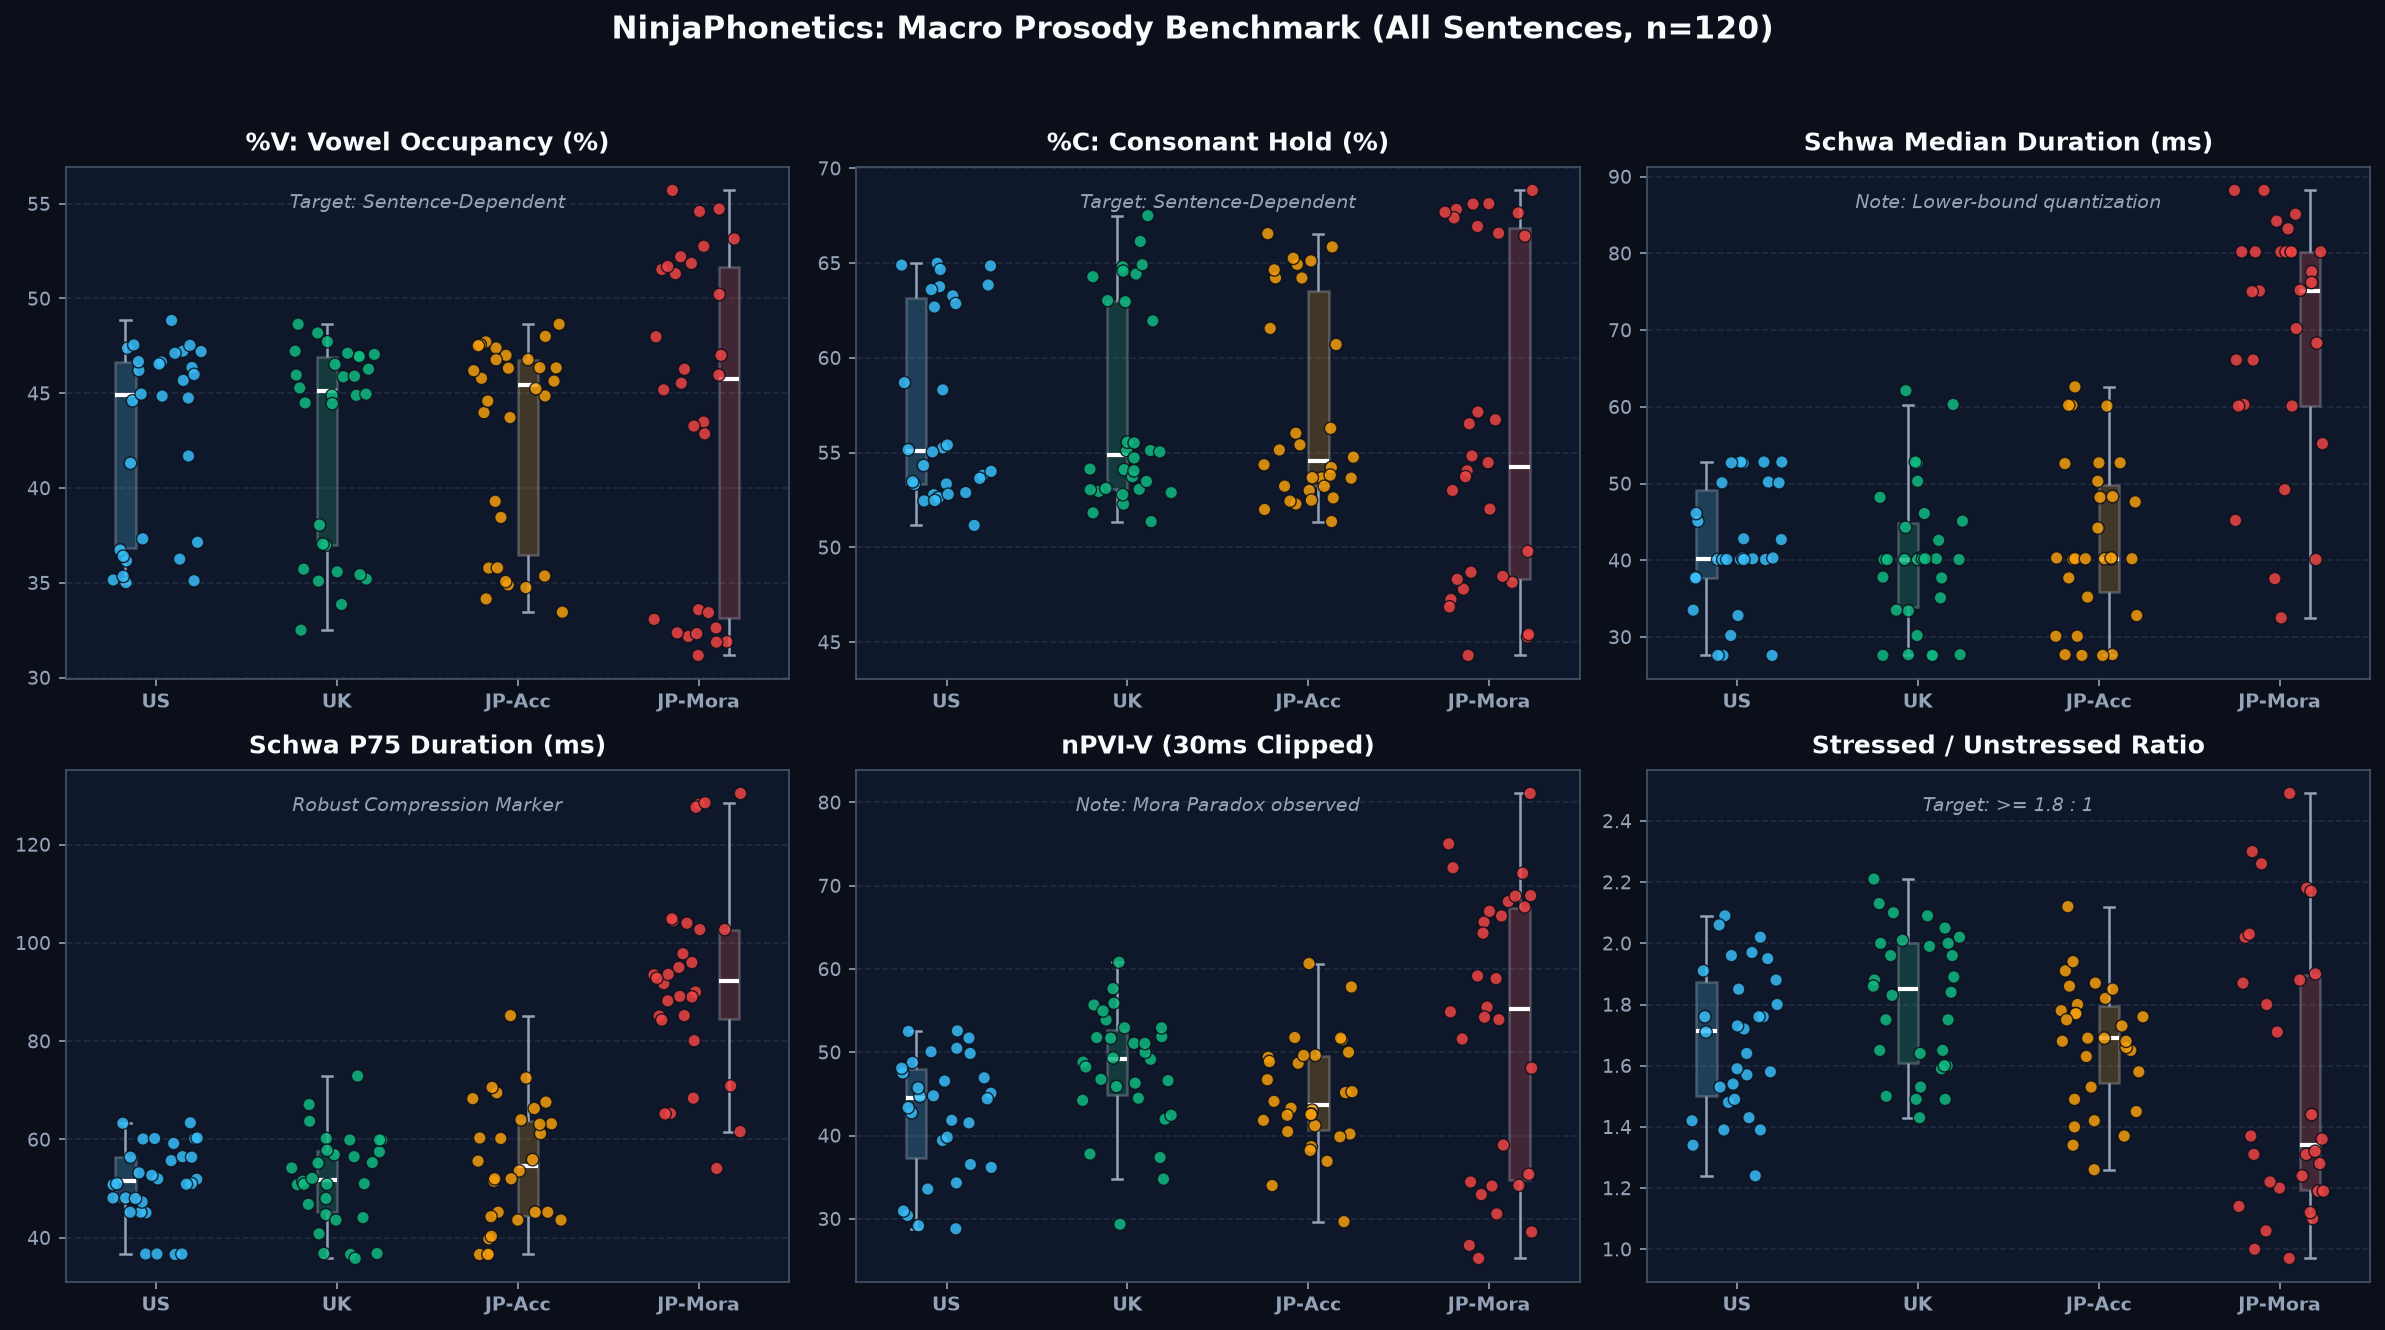

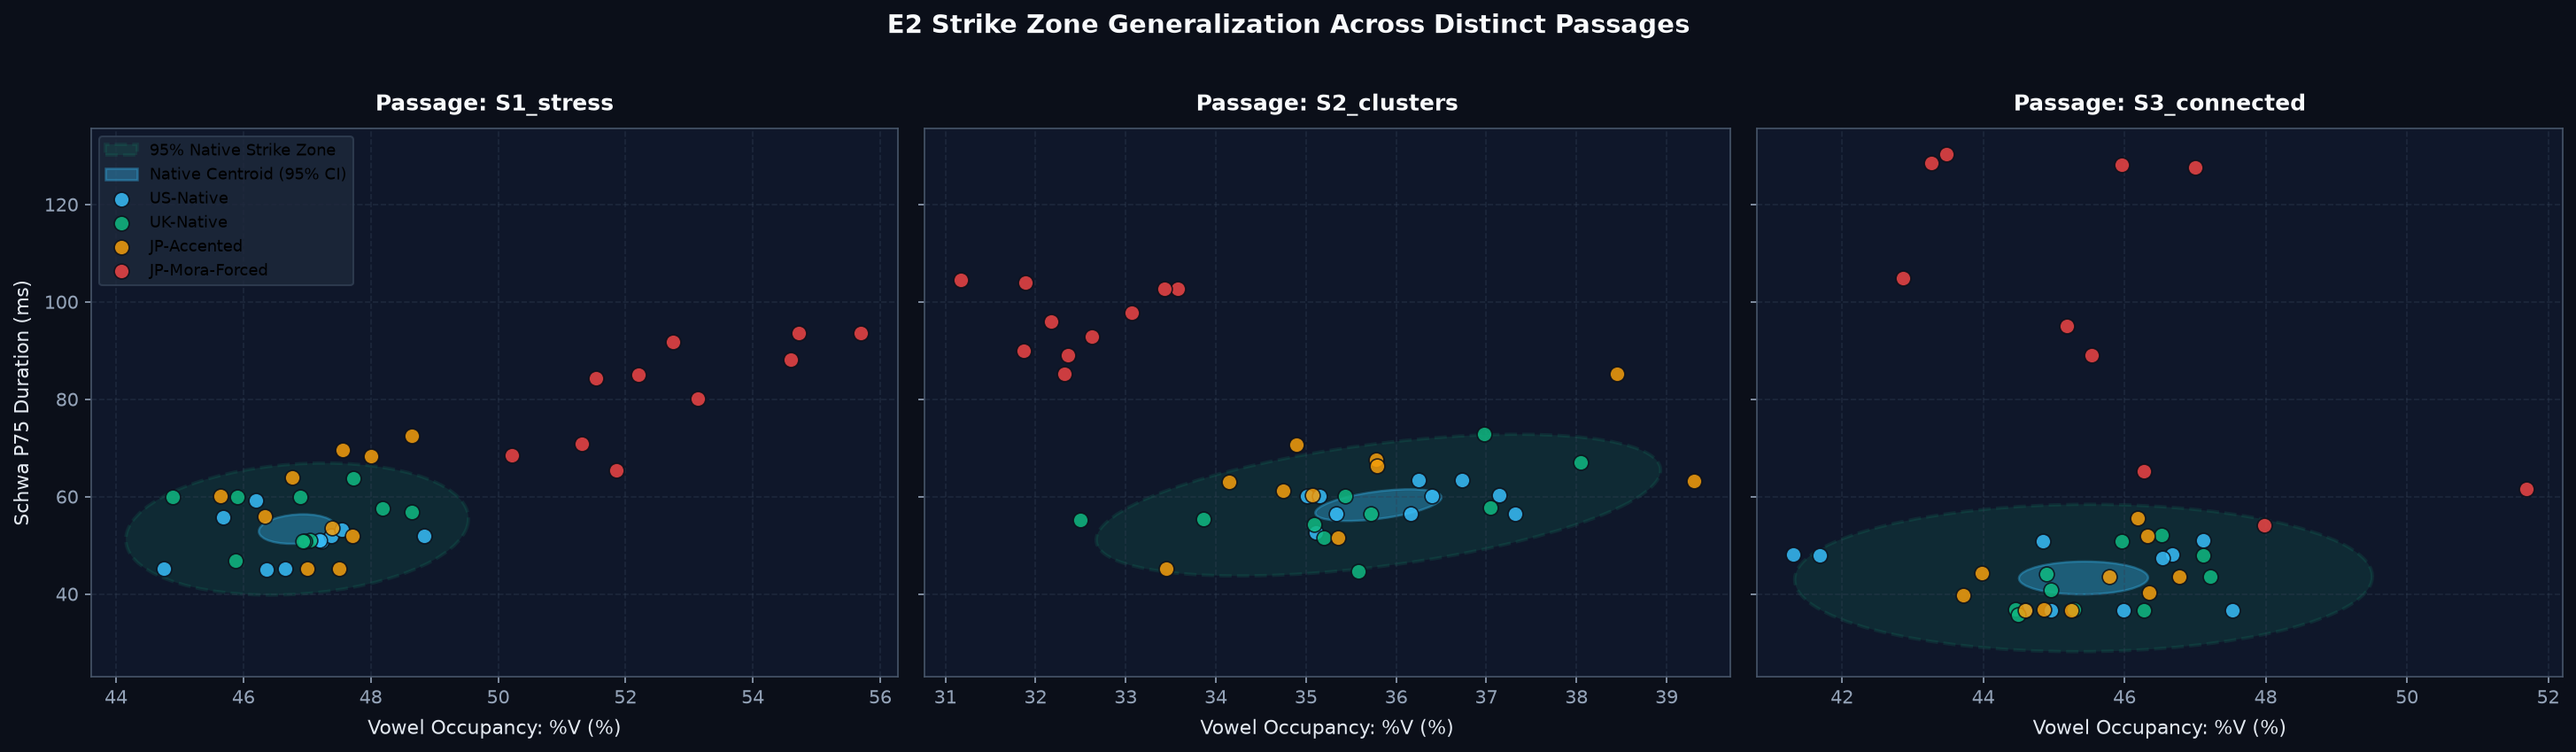

Sentence,S1_stress,S2_clusters,S3_connected,Mean_d
Metric,,,,
schwa_p75_ms,3.82,6.07,3.09,4.33
schwa_median_ms,3.76,5.10,2.29,3.72
pct_c,4.45,2.95,0.25,2.55
pct_v,4.45,2.95,0.25,2.55
npvi_clipped,2.79,1.30,2.36,2.15
s_u_ratio_mean,0.12,2.73,0.40,1.08


In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.transforms as transforms
from matplotlib.patches import Ellipse
import seaborn as sns

# スタイル・フォント設定（Spike2 / 暗色テーマ）
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#475569'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#334155'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.5

# %%
# 1. データの読み込み（全3文の結果CSV）
csv_path = "benchmarks/benchmark_results_all.csv"
if not os.path.exists(csv_path):
    # 旧ファイルへのフォールバック
    csv_path = "benchmarks/benchmark_results.csv"

df = pd.read_csv(csv_path)

cohort_order = ["US-Native", "UK-Native", "JP-Accented", "JP-Mora-Forced"]
palette = {
    "US-Native": "#38BDF8",       # スカイブルー
    "UK-Native": "#10B981",       # エメラルドグリーン
    "JP-Accented": "#F59E0B",     # アンバー
    "JP-Mora-Forced": "#EF4444"   # レッド
}

df['cohort'] = pd.Categorical(df['cohort'], categories=cohort_order, ordered=True)

# sentence_key 列が存在しない（1文のみ）場合の安全策
if "sentence_key" not in df.columns:
    df["sentence_key"] = "S1_stress"

sentence_keys = sorted(df["sentence_key"].unique())

# %%
# 2. 6大指標のマルチプロット（文章別 Facet または全体）
# ※ sentence_key ごとに色分けやグリッドを切り替えて分布を確認
metrics_to_plot = [
    ("pct_v", "%V: Vowel Occupancy (%)", "Target: Sentence-Dependent"),
    ("pct_c", "%C: Consonant Hold (%)", "Target: Sentence-Dependent"),
    ("schwa_median_ms", "Schwa Median Duration (ms)", "Note: Lower-bound quantization"),
    ("schwa_p75_ms", "Schwa P75 Duration (ms)", "Robust Compression Marker"),
    ("npvi_clipped", "nPVI-V (30ms Clipped)", "Note: Mora Paradox observed"),
    ("s_u_ratio_mean", "Stressed / Unstressed Ratio", "Target: >= 1.8 : 1")
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=150)
fig.patch.set_facecolor('#0B0F19')
axes = axes.flatten()

for idx, (col, title, subtitle) in enumerate(metrics_to_plot):
    ax = axes[idx]
    ax.set_facecolor('#0F172A')
    
    sns.boxplot(
        data=df,
        x='cohort',
        y=col,
        hue='cohort',
        legend=False,
        order=cohort_order,
        palette=palette,
        ax=ax,
        width=0.45,
        boxprops=dict(alpha=0.25, edgecolor='#E2E8F0', linewidth=1.2),
        whiskerprops=dict(color='#94A3B8', linewidth=1.2),
        capprops=dict(color='#94A3B8', linewidth=1.2),
        medianprops=dict(color='#FFFFFF', linewidth=2.0),
        showfliers=False
    )
    
    # 複数文ある場合はマーカー形状や散布で確認
    sns.stripplot(
        data=df,
        x='cohort',
        y=col,
        hue='cohort',
        legend=False,
        order=cohort_order,
        palette=palette,
        ax=ax,
        size=6,
        jitter=0.25,
        alpha=0.85,
        edgecolor='#0B0F19',
        linewidth=0.7
    )
    
    ax.set_title(title, fontsize=12, fontweight='bold', color='#F8FAFC', pad=8)
    ax.text(0.5, 0.92, subtitle, transform=ax.transAxes, ha='center',
            fontsize=9.0, color='#94A3B8', style='italic')
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(colors='#94A3B8', labelsize=9)
    ax.grid(True, axis='y')
    
    labels = ["US", "UK", "JP-Acc", "JP-Mora"]
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=0, fontweight='bold')

plt.suptitle(f"NinjaPhonetics: Macro Prosody Benchmark (All Sentences, n={len(df)})", 
             fontsize=15, fontweight='bold', color='#F8FAFC', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("benchmarks/prosody_distribution_all.png", facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()

# %%
# 3. 2D 散布図 ＆ 95% 許容楕円（Sentence ごとの Strike Zone 移動を比較）
def draw_confidence_ellipse(x, y, ax, n_std=2.447, facecolor='#10B981', alpha=0.15, **kwargs):
    """主軸回転（固有値分解）による 95% Bivariate Normal 許容楕円の描画"""
    x = np.asarray(x)
    y = np.asarray(y)
    if len(x) < 3:
        return None
    cov = np.cov(x, y)
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    width, height = 2 * n_std * np.sqrt(np.maximum(vals, 0))
    ellipse = Ellipse(
        xy=(np.mean(x), np.mean(y)),
        width=width,
        height=height,
        angle=theta,
        facecolor=facecolor,
        alpha=alpha,
        **kwargs
    )
    return ax.add_patch(ellipse)

n_sent = len(sentence_keys)
fig, axes = plt.subplots(1, n_sent, figsize=(6.5 * n_sent, 5.5), dpi=150, sharey=True)
fig.patch.set_facecolor('#0B0F19')
if n_sent == 1:
    axes = [axes]

for s_idx, s_key in enumerate(sentence_keys):
    ax = axes[s_idx]
    ax.set_facecolor('#0F172A')
    sub_df = df[df['sentence_key'] == s_key]
    
    # ネイティブ群（US + UK）の楕円を計算
    native_sub = sub_df[sub_df['cohort'].isin(["US-Native", "UK-Native"])]
    if len(native_sub) >= 3:
        draw_confidence_ellipse(
            native_sub['pct_v'], 
            native_sub['schwa_p75_ms'], 
            ax, 
            n_std=2.447, 
            facecolor='#10B981', 
            alpha=0.12, 
            edgecolor='#10B981', 
            linestyle='--', 
            linewidth=1.8, 
            label='95% Native Strike Zone'
        )
        # 中心点（Mean Centroid 95% CI）
        draw_confidence_ellipse(
            native_sub['pct_v'], 
            native_sub['schwa_p75_ms'], 
            ax, 
            n_std=2.447 / np.sqrt(len(native_sub)), 
            facecolor='#38BDF8', 
            alpha=0.35, 
            edgecolor='#38BDF8', 
            linewidth=1.2, 
            label='Native Centroid (95% CI)'
        )

    # 各コホートの散布
    for cohort_name in cohort_order:
        c_sub = sub_df[sub_df['cohort'] == cohort_name]
        ax.scatter(
            c_sub['pct_v'], c_sub['schwa_p75_ms'],
            color=palette[cohort_name],
            label=cohort_name,
            s=65, alpha=0.85, edgecolors='#0B0F19', linewidth=0.8,
            zorder=3
        )
        
    ax.set_title(f"Passage: {s_key}", fontsize=12, fontweight='bold', color='#F8FAFC', pad=10)
    ax.set_xlabel("Vowel Occupancy: %V (%)", fontsize=10.5, color='#E2E8F0', labelpad=6)
    if s_idx == 0:
        ax.set_ylabel("Schwa P75 Duration (ms)", fontsize=10.5, color='#E2E8F0', labelpad=6)
    
    ax.tick_params(colors='#94A3B8')
    ax.grid(True, linestyle='--', alpha=0.4, color='#334155')

axes[0].legend(frameon=True, facecolor='#1E293B', edgecolor='#334155', fontsize=8.5, loc='upper left')
plt.suptitle("E2 Strike Zone Generalization Across Distinct Passages", fontsize=14, fontweight='bold', color='#F8FAFC', y=1.02)
plt.tight_layout()
plt.savefig("benchmarks/prosody_2d_strike_zone_comparison.png", facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()

# %%
# 4. 文ごとの効果量 (Cohen's d: Native vs Mora) 比較
def cohens_d(group1, group2):
    n1, n2 = len(group1), len(group2)
    s1, s2 = np.var(group1, ddof=1), np.var(group2, ddof=1)
    s_pooled = np.sqrt(((n1 - 1) * s1 + (n2 - 1) * s2) / (n1 + n2 - 2))
    if s_pooled == 0:
        return 0.0
    return abs(np.mean(group1) - np.mean(group2)) / s_pooled

rows = []
eval_cols = ["pct_v", "pct_c", "schwa_p75_ms", "schwa_median_ms", "npvi_clipped", "s_u_ratio_mean"]

for s_key in sentence_keys:
    sub = df[df['sentence_key'] == s_key]
    nat = sub[sub['cohort'].isin(["US-Native", "UK-Native"])]
    mor = sub[sub['cohort'] == "JP-Mora-Forced"]
    
    for c in eval_cols:
        d_val = cohens_d(nat[c], mor[c])
        rows.append({"Sentence": s_key, "Metric": c, "Cohen's d": round(d_val, 2)})

ranking_df = pd.DataFrame(rows).pivot(index="Metric", columns="Sentence", values="Cohen's d")
ranking_df["Mean_d"] = ranking_df.mean(axis=1).round(2)
ranking_df.sort_values(by="Mean_d", ascending=False)